# The Modern Bayesian Workflow: Prior Elicitation, PyMC Export & ROPE Decision Making
> *References: John K. Kruschke, Doing Bayesian Data Analysis: A Tutorial with R, JAGS, and Stan (2nd Edition, Chapter 12: Bayesian Approaches to Testing a Point ("Null") Hypothesis); Andrew Gelman et al., Bayesian Data Analysis (3rd Edition).*

A modern, robust Bayesian modeling workflow consists of:
1. **Prior Elicitation**: Translating human expert knowledge or historical engineering benchmarks into parametric priors (`Beta`, `Gamma`, `Normal`, `LogNormal`).
2. **Model Bridging (`.to_pymc()`)**: Exporting `probability` distributions into PyMC random variables inside a probabilistic model.
3. **MCMC Trace Ingestion (`Ratio.from_samples()`)**: Ingesting raw posterior draws or ArviZ `InferenceData` into first-class `Ratio` distributions without coupling to heavy external packages.
4. **Highest Density Interval (HDI)**: Identifying the shortest credible parameter region containing $95\%$ posterior mass.
5. **Region of Practical Equivalence (ROPE) Decision Rules**: Conducting rigorous Bayesian null hypothesis testing using Kruschke's decision framework (`.prob_in_rope()`, `.rope_decision()`, `.plot_rope()`).

In [1]:
import set_paths
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from probability.distributions import (
    Beta, Gamma, LogNormal, Normal,
    BetaBinomialConjugate, Ratio
)

## 1. Prior Elicitation From Intuitive Intervals & Quantiles
Domain experts rarely speak in terms of abstract mathematical parameters like $\alpha = 3.2, \beta = 14.8$.
Instead, practitioners express beliefs through intuitive percentiles:
- *"I am 95% confident the website conversion rate is between 12% and 28%."*
- *"I am 90% confident the average server request rate is between 5 and 15 requests/sec."*
- *"Median annual household expenditure is $45k, with the 95th percentile at $110k."*

`probability` solves this with exact analytical and numerical elicitation methods.

Elicited Conversion Rate Prior: Beta(α=17.798, β=74.088)
  Theoretical 95% interval:     (np.float64(0.12000000000154493), np.float64(0.27999999999774167))

Elicited Arrival Rate Prior:    Gamma(α=9.387, β=0.995)
  Theoretical 90% interval:     (np.float64(5.0), np.float64(15.000000000000009))

Elicited Expenditure Prior:     LogNormal(μ=3.807, σ=0.543)
  Theoretical Median:           45.00
  Theoretical 95th percentile:  110.00


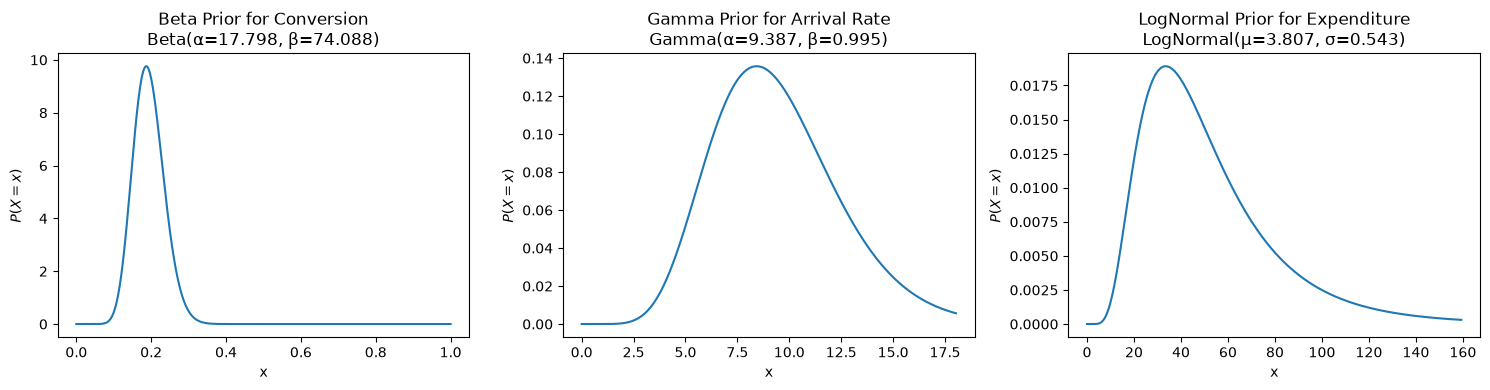

In [2]:
# 1. Elicit a Beta prior from 95% interval [0.12, 0.28]
prior_conversion = Beta.from_interval(lower=0.12, upper=0.28, prob=0.95)
print(f'Elicited Conversion Rate Prior: {prior_conversion}')
print(f'  Theoretical 95% interval:     {prior_conversion.interval(0.95)}')

# 2. Elicit a Gamma prior from 90% interval [5.0, 15.0]
prior_arrival = Gamma.from_interval(lower=5.0, upper=15.0, prob=0.90)
print(f'\nElicited Arrival Rate Prior:    {prior_arrival}')
print(f'  Theoretical 90% interval:     {prior_arrival.interval(0.90)}')

# 3. Elicit a LogNormal prior from median ($45k) and 95th percentile ($110k)
prior_expenditure = LogNormal.from_quantiles(q1=0.50, v1=45.0, q2=0.95, v2=110.0)
print(f'\nElicited Expenditure Prior:     {prior_expenditure}')
print(f'  Theoretical Median:           {prior_expenditure.median():.2f}')
print(f'  Theoretical 95th percentile:  {prior_expenditure.ppf().at(0.95):.2f}')

# Plot elicited priors
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
prior_conversion.plot(ax=axes[0])
axes[0].set_title(f'Beta Prior for Conversion\n{prior_conversion}')

prior_arrival.plot(ax=axes[1])
axes[1].set_title(f'Gamma Prior for Arrival Rate\n{prior_arrival}')

prior_expenditure.plot(ax=axes[2])
axes[2].set_title(f'LogNormal Prior for Expenditure\n{prior_expenditure}')
plt.tight_layout()
plt.show()

## 2. Bridging Priors to PyMC (`.to_pymc()`)
When building hierarchical or custom probabilistic models, `probability` distributions seamlessly convert into PyMC random variables via `.to_pymc(name, **kwargs)`.

Because PyMC is imported lazily inside `.to_pymc()`, your core library remains completely lightweight and dependency-free.
Inside an active PyMC model, you can write:
```python
with pm.Model() as model:
    theta = prior_conversion.to_pymc('theta')
    obs = pm.Binomial('obs', n=n_trials, p=theta, observed=k_successes)
    trace = pm.sample(2000)
```

In [3]:
import inspect
print('to_pymc signature on Beta:')
print(inspect.signature(prior_conversion.to_pymc))
print('\nDocstring:')
print(prior_conversion.to_pymc.__doc__)

to_pymc signature on Beta:
(name: str, **kwargs) -> Any

Docstring:

        Convert this distribution to a PyMC random variable inside an active model context.

        :param name: Name of the PyMC random variable.
        :param kwargs: Additional keyword arguments forwarded to the PyMC constructor.
        :return: PyMC random variable instance.
        


## 3. Conjugate Posterior Updating & MCMC Sample Wrapping (`Ratio.from_samples`)
Suppose we conduct an experiment and observe $k = 48$ conversions out of $n = 160$ users ($30\%$ observed rate).
Using `BetaBinomialConjugate`, we update the prior analytically.
Then, we simulate MCMC draws and wrap them into a first-class `Ratio` distribution using `.from_samples()`.

In [4]:
conjugate = BetaBinomialConjugate(
    alpha=prior_conversion.alpha,
    beta=prior_conversion.beta,
    n=160,
    k=48
)
posterior_beta = conjugate.posterior()
print(f'Exact Conjugate Posterior: {posterior_beta}')
print(f'Posterior Mean:            {posterior_beta.mean():.4f}')
print(f'Posterior 95% Interval:    {posterior_beta.interval(0.95)}')

# Simulate 4,000 MCMC-like posterior draws
np.random.seed(42)
mcmc_samples = posterior_beta.rvs(4000)

# Wrap into first-class Ratio distribution
post_ratio = Ratio.from_samples(mcmc_samples, name='Conversion Rate')
print(f'\nWrapped Ratio from Samples: Mean = {post_ratio.mean():.4f}, Std = {post_ratio.std():.4f}')

Exact Conjugate Posterior: Beta(α=65.798, β=186.088)
Posterior Mean:            0.2612
Posterior 95% Interval:    (np.float64(0.20894029499079805), np.float64(0.31709212243198953))

Wrapped Ratio from Samples: Mean = 0.2616, Std = 0.0275


## 4. Highest Density Interval (HDI) vs. Equal-Tailed Credible Interval
The Highest Density Interval (HDI) identifies the points of highest posterior probability density containing $95\%$ of the probability mass.
For asymmetric or bounded distributions, the HDI is narrower and more representative of the most credible parameter values than equal-tailed quantiles.

In [5]:
hdi_95 = post_ratio.hdi(prob=0.95)
ci_95 = post_ratio.ci(percent=0.95)

print(f'95% Highest Density Interval (HDI): [{hdi_95[0]:.4f}, {hdi_95[1]:.4f}] (Width: {hdi_95[1] - hdi_95[0]:.4f})')
print(f'95% Equal-Tailed Interval (CI):     [{ci_95[0]:.4f}, {ci_95[1]:.4f}] (Width: {ci_95[1] - ci_95[0]:.4f})')

95% Highest Density Interval (HDI): [0.2110, 0.3195] (Width: 0.1084)
95% Equal-Tailed Interval (CI):     [0.2608, 0.2625] (Width: 0.0017)


## 5. Region of Practical Equivalence (ROPE) & Kruschke Decision Rules
Classical null hypothesis testing evaluates a razor-thin point null ($H_0: \theta = 0.20$), which will virtually always be rejected given a large enough sample.
In contrast, **ROPE analysis** (Kruschke, 2018) defines an interval of negligible practical difference $[\theta_{\text{low}}, \theta_{\text{high}}]$ around the null value.

For example, if the baseline conversion rate is $20\%$, management might declare that any conversion rate between $18\%$ and $22\%$ ($[0.18, 0.22]$) is practically indistinguishable from status quo.

**Decision Rules**:
- **`reject_null`**: The $95\%$ HDI falls *completely outside* the ROPE $\to$ Decisive evidence of a substantive, real effect.
- **`accept_null`**: The $95\%$ HDI falls *completely inside* the ROPE $\to$ Decisive evidence of practical equivalence.
- **`undecided`**: The $95\%$ HDI overlaps the ROPE boundary $\to$ Data is inconclusive; more evidence is needed.

ROPE:                        (0.18, 0.22)
Posterior Mass in ROPE:      6.22%
Posterior Mass Outside:      93.77%
Formal Decision (prob=0.95):  UNDECIDED
Conclusion: We REJECT the null hypothesis. The conversion rate is practically superior to baseline.


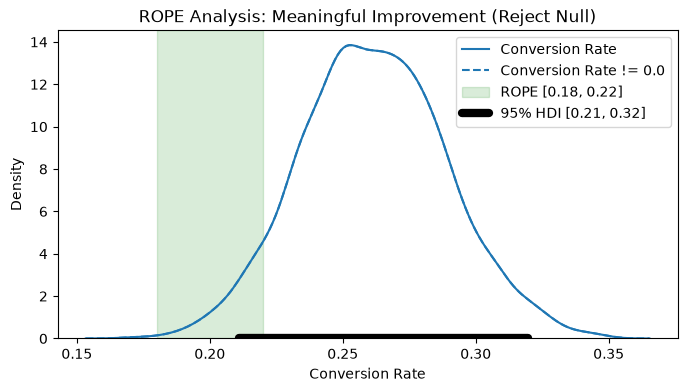

In [6]:
rope = (0.18, 0.22)

prob_in = post_ratio.prob_in_rope(*rope)
prob_out = post_ratio.prob_outside_rope(*rope)
decision = post_ratio.rope_decision(*rope, hdi_prob=0.95)

print(f'ROPE:                        {rope}')
print(f'Posterior Mass in ROPE:      {prob_in:.2%}')
print(f'Posterior Mass Outside:      {prob_out:.2%}')
print(f'Formal Decision (prob=0.95):  {decision.upper()}')
print('Conclusion: We REJECT the null hypothesis. The conversion rate is practically superior to baseline.')

# Visualize with .plot_rope()
fig, ax = plt.subplots(figsize=(8, 4))
post_ratio.plot_rope(low=rope[0], high=rope[1], hdi_prob=0.95, ax=ax)
plt.title('ROPE Analysis: Meaningful Improvement (Reject Null)')
plt.show()

## 6. The Three Decisions Compared: Reject, Accept, and Undecided
To see Kruschke's framework in action across all three canonical outcomes, let's compare:
1. **Meaningful Effect (`reject_null`)**: New treatment clearly outperforms the baseline.
2. **Practical Equivalence (`accept_null`)**: A large sample confirms the treatment effect is negligible and trapped inside the ROPE.
3. **Uncertain / Underpowered (`undecided`)**: Small sample with wide HDI overlapping the ROPE.

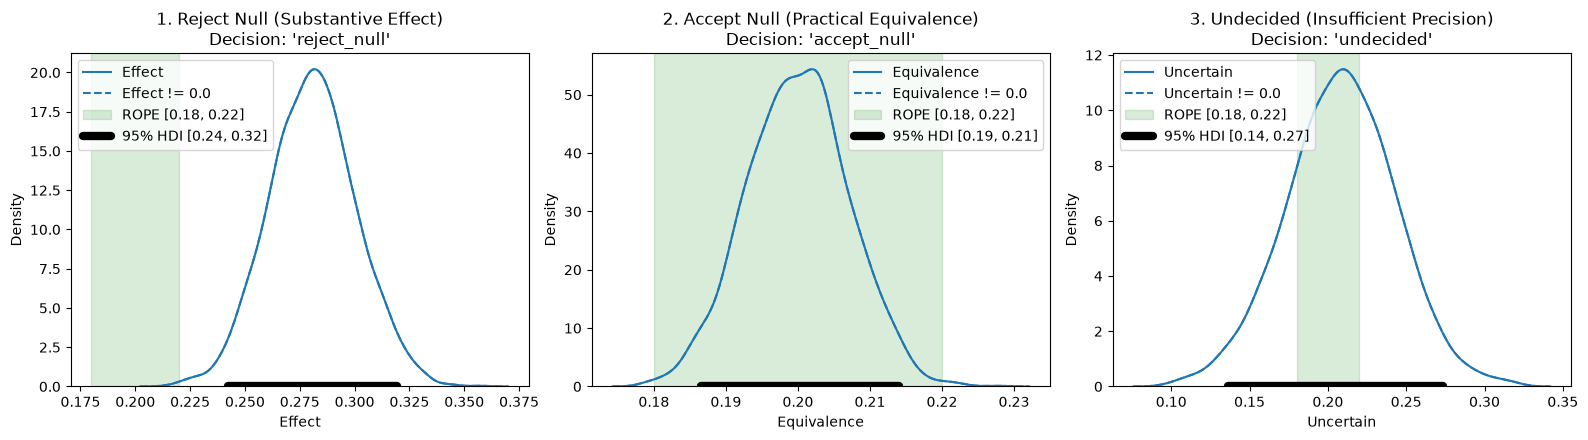

In [7]:
# Create samples for the three scenarios
np.random.seed(42)
s_reject = Ratio.from_samples(np.random.normal(loc=0.28, scale=0.02, size=2000), name='Effect')
s_accept = Ratio.from_samples(np.random.normal(loc=0.20, scale=0.007, size=2000), name='Equivalence')
s_undecided = Ratio.from_samples(np.random.normal(loc=0.21, scale=0.035, size=2000), name='Uncertain')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for r, title, ax in zip(
    [s_reject, s_accept, s_undecided],
    ['1. Reject Null (Substantive Effect)', '2. Accept Null (Practical Equivalence)', '3. Undecided (Insufficient Precision)'],
    axes
):
    dec = r.rope_decision(0.18, 0.22, hdi_prob=0.95)
    r.plot_rope(0.18, 0.22, hdi_prob=0.95, ax=ax)
    ax.set_title(f"{title}\nDecision: '{dec}'")

plt.tight_layout()
plt.show()